## Who Worked On This Part?
Muhammad Azaam Ali: trained and tuned the gradient boosting model (HistGradientBoosting).

# Mushroom: gradient boosting

**Gradient boosting** is the other big family of tree models. Where a random forest builds hundreds of *independent* trees and averages them, boosting builds small trees **one after the other**: every new tree tries to fix the mistakes the trees before it still make. The `learning_rate` sets how big a step each tree may take.

In PyCaret, gradient boosting with default settings was clearly below the random forest (AUC 0.78 vs 0.83). Boosting usually needs tuning more than a forest, so the question for this notebook: **does tuning close the gap?**

We use `HistGradientBoostingClassifier`, scikit-learn's fast version. It first sorts every numeric column into at most 255 bins, which makes training much faster. It's also the boosting model in our deployment code (`model/train.py`), so if it wins it can be trained on AWS without new code.

## Load the split
Same train and validation files as `3MushroomPredict.ipynb` and `3.1MushroomPyCaret.ipynb`, so all models are compared on exactly the same rows. The test file stays untouched until the compare notebook.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# walk up from where the notebook runs to the repo root, so the data path works on every machine
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'Mushroom' / 'datasets').is_dir())
DATA = ROOT / 'Mushroom' / 'datasets'

train_df = pd.read_csv(DATA / 'train.csv')
val_df = pd.read_csv(DATA / 'val.csv')

X_train, y_train = train_df.drop(columns='is_poisonous'), train_df['is_poisonous']
X_val, y_val = val_df.drop(columns='is_poisonous'), val_df['is_poisonous']

num_cols = ['cap_diameter_cm', 'stem_height_cm', 'stem_width_mm']
cat_cols = [c for c in X_train.columns if c not in num_cols]

X_train.shape, X_val.shape

((3500, 10), (750, 10))

## How we score a model
The same `evaluate()` as in `3MushroomPredict.ipynb`, so the numbers can be compared directly: ROC-AUC (ranking, no threshold), and recall / precision / F1 / accuracy at threshold 0.5.

In [2]:
from sklearn.metrics import roc_auc_score, recall_score, precision_score, f1_score, accuracy_score

def evaluate(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {
        'roc_auc': roc_auc_score(y_true, proba),
        'recall': recall_score(y_true, pred),
        'precision': precision_score(y_true, pred, zero_division=0),
        'f1': f1_score(y_true, pred),
        'accuracy': accuracy_score(y_true, pred),
    }

## The pipeline
Same as for the random forest: one-hot for the categories, numbers passed through unchanged (trees don't care about scale). One difference: `HistGradientBoostingClassifier` needs a normal table, not the compressed "sparse" matrix the encoder gives by default, hence `sparse_output=False`.

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier

prep = ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)], remainder='passthrough')

hgb = Pipeline([
    ('prep', prep),
    ('hgb', HistGradientBoostingClassifier(random_state=42)),
])
hgb.fit(X_train, y_train)

pd.DataFrame({
    'hgb default (train)': evaluate(y_train, hgb.predict_proba(X_train)[:, 1]),
    'hgb default (val)': evaluate(y_val, hgb.predict_proba(X_val)[:, 1]),
}).T.round(3)

,roc_auc,recall,precision,f1,accuracy
hgb default (train),0.967,0.773,0.934,0.846,0.893
hgb default (val),0.834,0.592,0.796,0.679,0.788


### What this tells us
The default HistGradientBoosting already does much better than PyCaret's gradient boosting: cross-validated AUC 0.815 against 0.776 (validation AUC 0.834). It's a different implementation with different defaults: it builds bigger trees (up to 31 leaves instead of depth 3), so it learns more per tree. It is still a little below the random forest (validation 0.834 vs 0.848).

The gap between train and validation is smaller than for the forest: train AUC 0.967 against validation 0.834, while the forest had 1.0 against 0.848. Boosting builds small trees with a limited number of rounds, so it memorises less than fully grown forest trees. A smaller gap doesn't make it the better model, though: the validation score is what counts, and there the forest is ahead.

## Tuning
The settings that matter most for boosting:
- `learning_rate`: how much each new tree may correct. Small = careful, needs more trees
- `max_iter`: the number of trees, one after the other
- `max_leaf_nodes`: how big each tree may get
- `min_samples_leaf`: the minimum number of mushrooms in a leaf (bigger = less memorising of single rows)
- `l2_regularization`: a brake on extreme leaf values

That's 4 × 4 × 4 × 4 × 4 = 1024 combinations: with 5 folds, 5120 models. Too many to try them all, so we use **`RandomizedSearchCV`**: it tries `n_iter=30` random combinations from the grid. Most combinations are about equally good, so 30 random tries usually find one close to the best, for 3% of the work. A higher `n_iter` raises the chance of finding the best combination, but with diminishing returns.

In [4]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
search = RandomizedSearchCV(
    hgb,
    param_distributions={
        'hgb__learning_rate': [0.01, 0.03, 0.05, 0.1],
        'hgb__max_iter': [100, 200, 400, 800],
        'hgb__max_leaf_nodes': [7, 15, 31, 63],
        'hgb__min_samples_leaf': [5, 10, 20, 40],
        'hgb__l2_regularization': [0, 0.1, 1, 10],
    },
    n_iter=30,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1,
    random_state=42,  # the same 30 combinations every run
)
search.fit(X_train, y_train)

results = pd.DataFrame(search.cv_results_)
print('worst of the 30:', round(results['mean_test_score'].min(), 3))
results.sort_values('rank_test_score')[['param_hgb__learning_rate', 'param_hgb__max_iter', 'param_hgb__max_leaf_nodes', 'param_hgb__min_samples_leaf', 'param_hgb__l2_regularization', 'mean_test_score', 'std_test_score']].head(8).round(3)

worst of the 30: 0.72


,param_hgb__learning_rate,param_hgb__max_iter,param_hgb__max_leaf_nodes,param_hgb__min_samples_leaf,param_hgb__l2_regularization,mean_test_score,std_test_score
14,0.03,400,63,10,1.0,0.822,0.015
15,0.05,100,63,10,1.0,0.822,0.014
23,0.01,800,31,5,0.1,0.821,0.017
8,0.03,100,63,5,0.0,0.819,0.015
4,0.03,400,31,20,1.0,0.818,0.012
26,0.03,400,31,20,0.1,0.817,0.011
17,0.05,400,31,10,0.1,0.816,0.015
25,0.05,800,31,5,1.0,0.816,0.013


To judge the tuning fairly, we also need the cross-validation score of the **default** model on the same 5 folds. Comparing a cross-validation score with a validation score would mix two different measurements.

In [5]:
from sklearn.model_selection import cross_val_score

default_cv = cross_val_score(hgb, X_train, y_train, cv=cv, scoring='roc_auc')
print('default: cv AUC', round(default_cv.mean(), 3), '±', round(default_cv.std(), 3))
print('tuned:   cv AUC', round(search.best_score_, 3), '±', round(results.loc[search.best_index_, 'std_test_score'], 3))
print('best settings:', search.best_params_)

default: cv AUC 0.815 ± 0.01
tuned:   cv AUC 0.822 ± 0.015
best settings: {'hgb__min_samples_leaf': 10, 'hgb__max_leaf_nodes': 63, 'hgb__max_iter': 400, 'hgb__learning_rate': 0.03, 'hgb__l2_regularization': 1}


In [6]:
hgb_tuned = search.best_estimator_

pd.DataFrame({
    'hgb default (val)': evaluate(y_val, hgb.predict_proba(X_val)[:, 1]),
    'hgb tuned (train)': evaluate(y_train, hgb_tuned.predict_proba(X_train)[:, 1]),
    'hgb tuned (val)': evaluate(y_val, hgb_tuned.predict_proba(X_val)[:, 1]),
}).T.round(3)

,roc_auc,recall,precision,f1,accuracy
hgb default (val),0.834,0.592,0.796,0.679,0.788
hgb tuned (train),0.997,0.915,0.983,0.948,0.962
hgb tuned (val),0.829,0.577,0.770,0.660,0.775


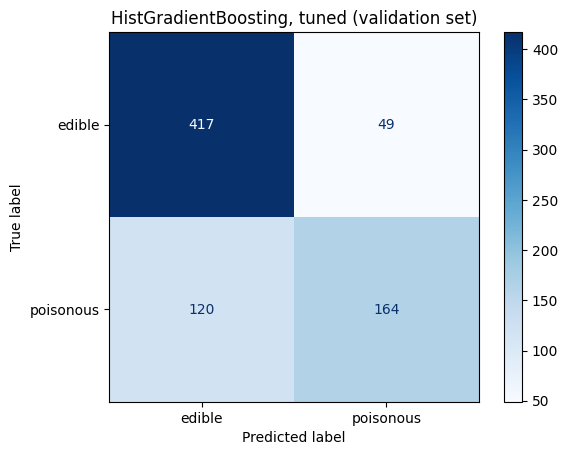

In [7]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_val, hgb_tuned.predict(X_val), display_labels=['edible', 'poisonous'], cmap='Blues')
plt.title('HistGradientBoosting, tuned (validation set)')
plt.show()

### What this tells us
In cross-validation tuning gained 0.007 AUC (0.815 → 0.822), less than the spread between folds (0.010 to 0.015). On validation the tuned model is even slightly **worse** (0.834 → 0.829). Both differences are within the noise, so tuning did not really improve the model.

When the two disagree, we trust **cross-validation** more: it averages 5 scores over all 3500 training rows, while validation is one score on 750 rows (284 poisonous), where a handful of mushrooms can move the AUC by 0.005.

The worst of the 30 combinations scored 0.72, the best 0.82: boosting is more **sensitive** to its settings than the forest, whose 24 combinations ranged from 0.77 to 0.83. With good settings it gets close to the forest, with bad ones it falls back towards logistic regression. The best combinations use a small learning rate (0.01 to 0.05) with enough trees, the usual pattern for boosting.

## Save the model
The whole pipeline (one-hot encoding + model) goes to `models/hist_gradient_boosting.pkl`, next to `logreg.pkl`. The compare notebook loads all saved models and scores them on the same data. GitHub refuses files over 100 MB, so we print the size.

In [8]:
import joblib

MODELS = ROOT / 'Mushroom' / 'models'
MODELS.mkdir(exist_ok=True)
joblib.dump(hgb_tuned, MODELS / 'hist_gradient_boosting.pkl', compress=3)  # compress: a forest of hundreds of trees is big otherwise
print(round((MODELS / 'hist_gradient_boosting.pkl').stat().st_size / 1e6, 1), 'MB')

1.1 MB


## Conclusion
Tuning did not close the gap with the random forest. The default HistGradientBoosting is already good (validation AUC 0.834, far above PyCaret's gradient boosting), but RandomizedSearchCV (30 combinations, 5-fold cross-validation) only gains 0.007 in cross-validation and loses 0.005 on validation, both within the noise. The tuned model reaches validation AUC 0.829, against 0.852 for the tuned forest.

We take the **random forest** to the compare notebook as the favourite: it has the best validation score, it barely depends on its settings, and it is more robust to the noisy labels. Boosting builds every tree to fix the errors of the previous ones, so mislabelled mushrooms keep getting extra attention, while the forest averages them away. HistGradientBoosting stays in the comparison as the second tree model.